# Monocular Single Human Pose Estimation

In [ ]:
! git clone https://github.com/microsoft/human-pose-estimation.pytorch && cd human-pose-estimation.pytorch && git checkout 18f1d0fa5b5db7fe08de640610f3fdbdbed8fb2f

Cloning into 'human-pose-estimation.pytorch'...
remote: Enumerating objects: 188, done.
remote: Total 188 (delta 0), reused 0 (delta 0), pack-reused 188
Receiving objects: 100% (188/188), 68.96 KiB | 6.27 MiB/s, done.
Resolving deltas: 100% (86/86), done.
Note: checking out '18f1d0fa5b5db7fe08de640610f3fdbdbed8fb2f'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by performing another checkout.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -b with the checkout command again. Example:

  git checkout -b <new-branch-name>

HEAD is now at 18f1d0f Update README.md


In [ ]:
! pip install onnx onnxruntime

     |████████████████████████████████| 14.5MB 218kB/s 
     |████████████████████████████████| 4.1MB 33.2MB/s 


In [ ]:
import sys
if "/content/human-pose-estimation.pytorch/lib/" not in sys.path:
    sys.path.insert(0, "/content/human-pose-estimation.pytorch/lib/")

In [ ]:
import re
import os
import cv2
import copy
import torch
import numpy as np
import torch.optim
import torch.nn as nn
from PIL import Image
import seaborn as sns
import matplotlib.pyplot as plt
import torchvision.transforms as T
import torch.backends.cudnn as cudnn

sns.set()

In [ ]:
ls

human-pose-estimation.pytorch/  sample_data/


In [ ]:
import models
from core.config import config
from core.config import update_dir
from core.config import update_config
from core.config import get_model_name

We are going to use MPII - ResNet50 Model trained on `256x256` sized images
model_file: https://drive.google.com/file/d/1V2AaVpDSn-eS7jrFScHLJ-wvTFuQ0-Dc/view?usp=sharing

In [ ]:
! gdown https://drive.google.com/uc?id=1V2AaVpDSn-eS7jrFScHLJ-wvTFuQ0-Dc

Downloading...
From: https://drive.google.com/uc?id=1V2AaVpDSn-eS7jrFScHLJ-wvTFuQ0-Dc
To: /content/pose_resnet_50_256x256.pth.tar
136MB [00:01, 131MB/s]


- **`The corresponding config file is taken from experiments folder`**

In [ ]:
CONFIG_FILE = '/content/human-pose-estimation.pytorch/experiments/mpii/resnet50/256x256_d256x3_adam_lr1e-3.yaml'
MODEL_PATH = '/content/pose_resnet_50_256x256.pth.tar'

In [ ]:
update_config(CONFIG_FILE)
config.GPUS = '' # we are running on CPU

Load the model

In [ ]:
model = eval('models.'+config.MODEL.NAME+'.get_pose_net')(config, is_train=False)
model.load_state_dict(torch.load(MODEL_PATH, map_location=torch.device('cpu')))

<All keys matched successfully>

In [ ]:
! wget https://github.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/blob/master/Images/vijay.png?raw=true -O Vijay.jpg

--2021-03-23 11:45:11--  https://github.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/blob/master/Images/vijay.png?raw=true
Resolving github.com (github.com)... 140.82.121.4
Connecting to github.com (github.com)|140.82.121.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/raw/master/Images/vijay.png [following]
--2021-03-23 11:45:11--  https://github.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/raw/master/Images/vijay.png
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/master/Images/vijay.png [following]
--2021-03-23 11:45:11--  https://raw.githubusercontent.com/VijayPrakashReddy-k/VijayPrakashReddy-k.github.io/master/Images/vijay.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.1

In [ ]:
IMAGE_FILE = 'Vijay.jpg'

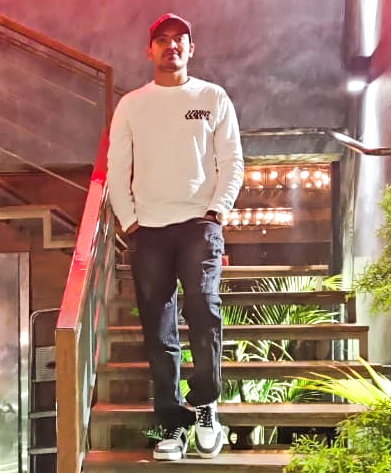

In [ ]:
image = Image.open(IMAGE_FILE)
image = image.convert('RGB')
image

In [ ]:
transform = T.Compose([
                       T.Resize((256, 256)),
                       T.ToTensor(),
                       T.Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])
                       ])

Transform the image for the model

In [ ]:
tr_img = transform(image)

Pass the Image through the model

In [ ]:
output = model(tr_img.unsqueeze(0))
output = output.squeeze(0)

In [ ]:
_, OUT_HEIGHT, OUT_WIDTH = output.shape
output.shape

torch.Size([16, 64, 64])

In [ ]:
get_detached = lambda x: copy.deepcopy(x.cpu().detach().numpy())

`joint_id` - name
taken from: http://human-pose.mpi-inf.mpg.de/#download

In [ ]:
JOINTS = ['0 - r ankle', '1 - r knee', '2 - r hip', '3 - l hip', '4 - l knee', '5 - l ankle', '6 - pelvis', '7 - thorax', '8 - upper neck', '9 - head top', '10 - r wrist', '11 - r elbow', '12 - r shoulder', '13 - l shoulder', '14 - l elbow', '15 - l wrist']
JOINTS = [re.sub(r'[0-9]+|-', '', joint).strip().replace(' ', '-') for joint in JOINTS]

In [ ]:
POSE_PAIRS = [
# UPPER BODY
              [9, 8],
              [8, 7],
              [7, 6],

# LOWER BODY
              [6, 2],
              [2, 1],
              [1, 0],

              [6, 3],
              [3, 4],
              [4, 5],

# ARMS
              [7, 12],
              [12, 11],
              [11, 10],

              [7, 13],
              [13, 14],
              [14, 15]
]

In [ ]:
from operator import itemgetter
get_keypoints = lambda pose_layers: map(itemgetter(1, 3), [cv2.minMaxLoc(pose_layer) for pose_layer in pose_layers])

Here are all the detections

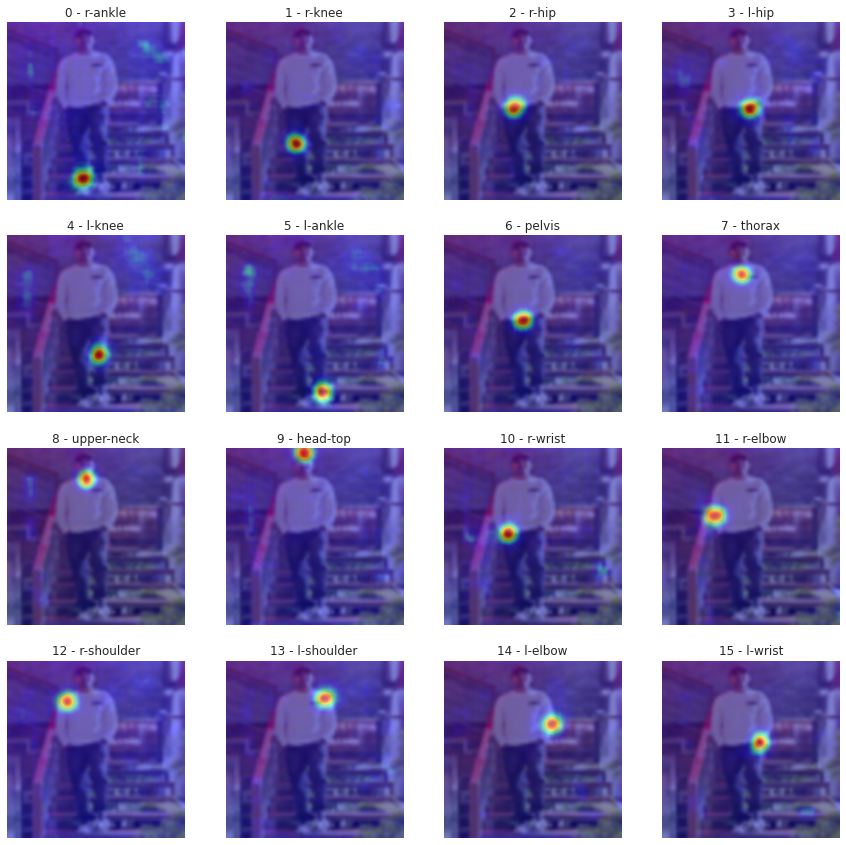

In [ ]:
plt.figure(figsize=(15, 15))
for idx, pose_layer in enumerate(get_detached(output)):
    # print(pose_layer.shape)
    plt.subplot(4, 4, idx + 1)
    plt.title(f'{idx} - {JOINTS[idx]}')
    plt.imshow(image.resize((OUT_WIDTH, OUT_HEIGHT)), cmap='gray', interpolation='bicubic')
    plt.imshow(pose_layer, alpha=0.5, cmap='jet', interpolation='bicubic')
    plt.axis('off')
plt.show()

Here are the detections summarised in a single image

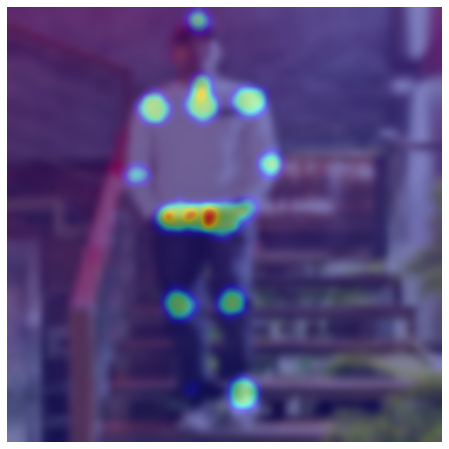

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(image.resize((OUT_WIDTH, OUT_HEIGHT)), cmap='gray', interpolation='bicubic')
pose_layers = get_detached(output)
pose_layers = np.clip(pose_layers, 0.7, 1.0)
layer_sum = np.sum(pose_layers, axis=0)
plt.imshow(layer_sum, alpha=0.5, cmap='jet', interpolation='bicubic')
plt.axis('off')
plt.show()

Now we will connect these detected regions

In [ ]:
THRESHOLD = 0.5
OUT_SHAPE = (OUT_HEIGHT, OUT_WIDTH)
image_p = cv2.imread(IMAGE_FILE)
pose_layers = get_detached(x=output)
key_points = list(get_keypoints(pose_layers=pose_layers))
is_joint_plotted = [False for i in range(len(JOINTS))]
for pose_pair in POSE_PAIRS:
    from_j, to_j = pose_pair

    from_thr, (from_x_j, from_y_j) = key_points[from_j]
    to_thr, (to_x_j, to_y_j) = key_points[to_j]

    IMG_HEIGHT, IMG_WIDTH, _ = image_p.shape

    from_x_j, to_x_j = from_x_j * IMG_WIDTH / OUT_SHAPE[0], to_x_j * IMG_WIDTH / OUT_SHAPE[0]
    from_y_j, to_y_j = from_y_j * IMG_HEIGHT / OUT_SHAPE[1], to_y_j * IMG_HEIGHT / OUT_SHAPE[1]

    from_x_j, to_x_j = int(from_x_j), int(to_x_j)
    from_y_j, to_y_j = int(from_y_j), int(to_y_j)

    if from_thr > THRESHOLD and not is_joint_plotted[from_j]:
        # this is a joint
        cv2.ellipse(image_p, (from_x_j, from_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[from_j] = True

    if to_thr > THRESHOLD and not is_joint_plotted[to_j]:
        # this is a joint
        cv2.ellipse(image_p, (to_x_j, to_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[to_j] = True

    if from_thr > THRESHOLD and to_thr > THRESHOLD:
        # this is a joint connection, plot a line
        cv2.line(image_p, (from_x_j, from_y_j), (to_x_j, to_y_j), (255, 74, 0), 3)

### Our final image with the estimated pose !

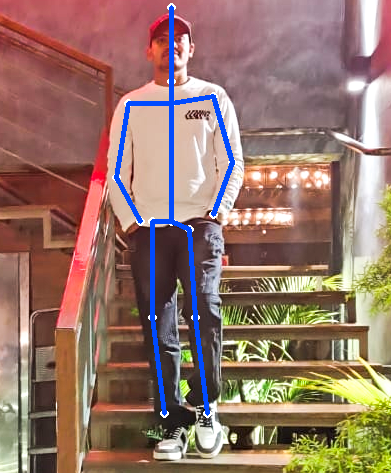

In [ ]:
Image.fromarray(cv2.cvtColor(image_p, cv2.COLOR_RGB2BGR))

## Convert to ONNX and quantize the model

In [ ]:
def print_size_of_model(model):
    torch.save(model.state_dict(), "temp.p")
    print('Size (MB):', os.path.getsize("temp.p")/1e6)
    os.remove('temp.p')

def print_size_of_onnx_model(model):
    onnx.save(model, 'temp.onnx')
    print('Size (MB):', os.path.getsize("temp.onnx")/1e6)
    os.remove('temp.onnx')

PyTorch Model Size

In [ ]:
print_size_of_model(model)

Size (MB): 136.330065


In [ ]:
new_model = copy.deepcopy(model)

Now we will Convert this model to ONNX

In [ ]:
import io
import numpy as np
import torch.onnx

In [ ]:
# Input to the model
torch_model = new_model
batch_size = 1
x = torch.randn(batch_size, 3, 256, 256, requires_grad=True)
torch_out = torch_model(x)

import torch.onnx

# Export the model
torch.onnx.export(torch_model,               # model being run
                  x,                         # model input (or a tuple for multiple inputs)
                  "simple_pose_estimation.onnx",   # where to save the model (can be a file or file-like object)
                  export_params=True,        # store the trained parameter weights inside the model file
                  opset_version=10,          # the ONNX version to export the model to
                  do_constant_folding=True,  # whether to execute constant folding for optimization
                  input_names = ['input'],   # the model's input names
                  output_names = ['output'], # the model's output names
                  dynamic_axes={'input' : {0 : 'batch_size'},    # variable lenght axes
                                'output' : {0 : 'batch_size'}})

In [ ]:
import onnx

onnx_model = onnx.load("simple_pose_estimation.onnx")
onnx.checker.check_model(onnx_model)

Let's just check the size of the saved ONNX Model

In [ ]:
print_size_of_onnx_model(onnx_model)

Size (MB): 135.910897


And also lets quicky test if the model works

In [ ]:
import onnxruntime

ort_session = onnxruntime.InferenceSession("simple_pose_estimation.onnx")

def to_numpy(tensor):
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()

# compute ONNX Runtime output prediction
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(tr_img.unsqueeze(0))}
ort_outs = ort_session.run(None, ort_inputs)

In [ ]:
ort_outs = ort_outs[0][0]

In [ ]:
len(ort_outs)

16

### ONNX Model Quantization

In [ ]:
from onnxruntime.quantization import quantize
from onnxruntime.quantization import QuantizationMode

quantized_model = quantize(onnx_model, quantization_mode=QuantizationMode.IntegerOps, static=False)

         Please use quantize_static for static quantization, quantize_dynamic for dynamic quantization.


In [ ]:
quantized_model = quantize(onnx_model, quantization_mode=QuantizationMode.IntegerOps, static=False)

         Please use quantize_static for static quantization, quantize_dynamic for dynamic quantization.


In [ ]:
onnx.save(quantized_model, 'simple_pose_estimation_quantized.onnx')

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
model_save_name = 'pose_resnet_50_256x256.pth.tar'
path = F"/content/gdrive/My Drive/EVA5/HPE/Models/{model_save_name}" 
torch.save(model.state_dict(), path)

In [ ]:
model_save_name = 'simple_pose_estimation_quantized.onnx'
path = F"/content/gdrive/My Drive/EVA5/HPE/Models/{model_save_name}" 
torch.save(model.state_dict(), path)

The Quantized Model is Half the Size

In [ ]:
model_save_name = 'simple_pose_estimation.onnx'
path = F"/content/gdrive/My Drive/EVA5/HPE/Models/{model_save_name}" 
torch.save(model.state_dict(), path)

In [ ]:
print_size_of_onnx_model(quantized_model)

Size (MB): 65.620732


Let's now test if the quantized model works

In [ ]:
ls

gdrive/                         simple_pose_estimation.onnx
human-pose-estimation.pytorch/  simple_pose_estimation_quantized.onnx
pose_resnet_50_256x256.pth.tar  Vijay.jpg
sample_data/


In [ ]:
from google.colab import files

In [ ]:
files.download("simple_pose_estimation_quantized.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("simple_pose_estimation.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import onnxruntime

ort_session = onnxruntime.InferenceSession("simple_pose_estimation_quantized.onnx")

def to_numpy(tensor):
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()

# compute ONNX Runtime output prediction
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(tr_img.unsqueeze(0))}
ort_outs = ort_session.run(None, ort_inputs)

In [ ]:
np.array(ort_outs).shape

(1, 1, 16, 64, 64)

In [ ]:
ort_outs = np.array(ort_outs[0][0])

In [ ]:
THRESHOLD = 0.6
OUT_SHAPE = (OUT_HEIGHT, OUT_WIDTH)
image_p = cv2.imread(IMAGE_FILE)
pose_layers = ort_outs
key_points = list(get_keypoints(pose_layers=pose_layers))
is_joint_plotted = [False for i in range(len(JOINTS))]
for pose_pair in POSE_PAIRS:
    from_j, to_j = pose_pair

    from_thr, (from_x_j, from_y_j) = key_points[from_j]
    to_thr, (to_x_j, to_y_j) = key_points[to_j]

    IMG_HEIGHT, IMG_WIDTH, _ = image_p.shape

    from_x_j, to_x_j = from_x_j * IMG_WIDTH / OUT_SHAPE[0], to_x_j * IMG_WIDTH / OUT_SHAPE[0]
    from_y_j, to_y_j = from_y_j * IMG_HEIGHT / OUT_SHAPE[1], to_y_j * IMG_HEIGHT / OUT_SHAPE[1]

    from_x_j, to_x_j = int(from_x_j), int(to_x_j)
    from_y_j, to_y_j = int(from_y_j), int(to_y_j)

    if from_thr > THRESHOLD and not is_joint_plotted[from_j]:
        # this is a joint
        cv2.ellipse(image_p, (from_x_j, from_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[from_j] = True

    if to_thr > THRESHOLD and not is_joint_plotted[to_j]:
        # this is a joint
        cv2.ellipse(image_p, (to_x_j, to_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[to_j] = True

    if from_thr > THRESHOLD and to_thr > THRESHOLD:
        # this is a joint connection, plot a line
        cv2.line(image_p, (from_x_j, from_y_j), (to_x_j, to_y_j), (255, 74, 0), 3)

Pretty similar results !? eh ?

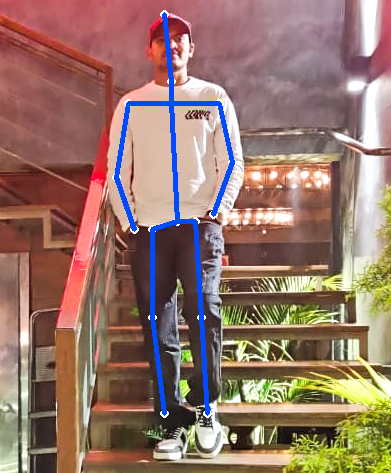

In [ ]:
Image.fromarray(cv2.cvtColor(image_p, cv2.COLOR_RGB2BGR))

In [ ]:
!pip install boto3

     |████████████████████████████████| 133kB 10.2MB/s 
     |████████████████████████████████| 7.3MB 15.8MB/s 
     |████████████████████████████████| 81kB 8.5MB/s 
     |████████████████████████████████| 153kB 41.5MB/s 
ERROR: requests 2.23.0 has requirement urllib3!=1.25.0,!=1.25.1,<1.26,>=1.21.1, but you'll have urllib3 1.26.4 which is incompatible.
ERROR: datascience 0.10.6 has requirement folium==0.2.1, but you'll have folium 0.8.3 which is incompatible.
  Found existing installation: urllib3 1.24.3
    Uninstalling urllib3-1.24.3:
      Successfully uninstalled urllib3-1.24.3


### Connect to AWS S3 bucket, to check the inference with the uploaded model

### Provide your access key and secret key following

In [ ]:
import boto3

In [ ]:
s3 = boto3.resource('s3', aws_access_key_id='XXXXXXXXXXXXXXXXXXXX',
    aws_secret_access_key='XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX')

In [ ]:
buck = s3.Bucket('aws-bucket-name')

In [ ]:
for obj in buck.objects.all():
    key = obj.key
    body = obj.get()['Body'].read()

In [ ]:
key

'simple_pose_estimation_quantized.onnx'

In [ ]:
body

In [ ]:
import onnxruntime

ort_session = onnxruntime.InferenceSession(body)

def to_numpy(tensor):
    return tensor.detach().cpu().numpy() if tensor.requires_grad else tensor.cpu().numpy()

# compute ONNX Runtime output prediction
ort_inputs = {ort_session.get_inputs()[0].name: to_numpy(tr_img.unsqueeze(0))}
ort_outs = ort_session.run(None, ort_inputs)

In [ ]:
np.array(ort_outs).shape

(1, 1, 16, 64, 64)

In [ ]:
ort_outs = np.array(ort_outs[0][0])

In [ ]:
THRESHOLD = 0.6
OUT_SHAPE = (OUT_HEIGHT, OUT_WIDTH)
image_p = cv2.imread(IMAGE_FILE)
pose_layers = ort_outs
key_points = list(get_keypoints(pose_layers=pose_layers))
is_joint_plotted = [False for i in range(len(JOINTS))]
for pose_pair in POSE_PAIRS:
    from_j, to_j = pose_pair

    from_thr, (from_x_j, from_y_j) = key_points[from_j]
    to_thr, (to_x_j, to_y_j) = key_points[to_j]

    IMG_HEIGHT, IMG_WIDTH, _ = image_p.shape

    from_x_j, to_x_j = from_x_j * IMG_WIDTH / OUT_SHAPE[0], to_x_j * IMG_WIDTH / OUT_SHAPE[0]
    from_y_j, to_y_j = from_y_j * IMG_HEIGHT / OUT_SHAPE[1], to_y_j * IMG_HEIGHT / OUT_SHAPE[1]

    from_x_j, to_x_j = int(from_x_j), int(to_x_j)
    from_y_j, to_y_j = int(from_y_j), int(to_y_j)

    if from_thr > THRESHOLD and not is_joint_plotted[from_j]:
        # this is a joint
        cv2.ellipse(image_p, (from_x_j, from_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[from_j] = True

    if to_thr > THRESHOLD and not is_joint_plotted[to_j]:
        # this is a joint
        cv2.ellipse(image_p, (to_x_j, to_y_j), (4, 4), 0, 0, 360, (255, 255, 255), cv2.FILLED)
        is_joint_plotted[to_j] = True

    if from_thr > THRESHOLD and to_thr > THRESHOLD:
        # this is a joint connection, plot a line
        cv2.line(image_p, (from_x_j, from_y_j), (to_x_j, to_y_j), (255, 74, 0), 3)

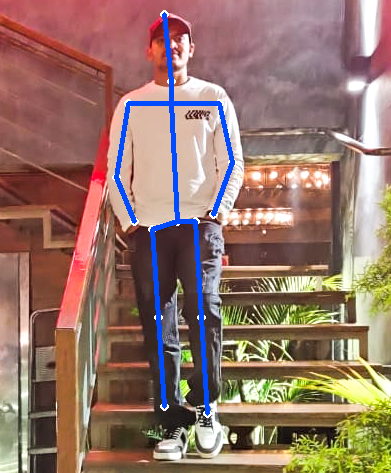

In [ ]:
Image.fromarray(cv2.cvtColor(image_p, cv2.COLOR_RGB2BGR))